# Modeling Funnel

This notebook profiles predictors and evaluates them through univariate, bivariate, and multivariate stages.

Feature types are identified explicitly: numeric, boolean, datetime, categorical, or other. The final selected list includes only predictors that pass all three selection stages. The current bivariate threshold is defined for numeric predictors; other types are profiled separately and are not automatically treated as categorical or selected.

## 1. Configuration

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Resolve the project root from either the project root or this notebook's folder.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = Path.cwd().parents[1]

# Essential parameters
INPUT = PROJECT_ROOT / "data" / "master_listing.parquet"
TARGET = "market_price_observation__first_asking_rent"
MIN_COMPLETENESS = 70

# Analysis thresholds
BIVARIATE_THRESHOLD = 0.10
MULTIVARIATE_THRESHOLD = 0.80
CORRELATION_METHOD = "spearman"

In [2]:
pd.set_option('display.max_columns', None)

## 2. Utilities and Data Loading

In [3]:
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "modeling_funnel"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not INPUT.exists():
    raise FileNotFoundError(f"Input file not found: {INPUT.resolve()}")

df = pd.read_parquet(INPUT)

if TARGET not in df.columns:
    raise KeyError(f"Target column '{TARGET}' was not found in the input file.")

print(f"Loaded dataset: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
display(df.head())

Loaded dataset: 967,661 rows × 378 columns


,unit_id,property_id,floor_plan_id,market,market_unit__unit_name,market_unit__floorplan_name,market_unit__bed,market_unit__bath,market_unit__partial_bath,market_unit__floor,market_unit__sqft,market_unit__days_on_market,market_unit__availability,market_unit__enter_market,market_unit__exit_market,market_unit__created_on,market_unit__url,market_unit__status,truth_lease_event__physical_unit_id,truth_lease_event__outcome,truth_lease_event__true_lease_start,truth_lease_event__true_lease_end,truth_lease_event__true_term_months,truth_lease_event__true_rent,truth_lease_event__true_concession_monthly,truth_lease_event__true_effective_rent,truth_lease_event__true_move_in,truth_lease_event__inferred_lease_start,truth_lease_event__inferred_lease_end,truth_lease_event__inferred_term_months,truth_lease_event__true_market_rent_at_signing,market_floor_plan__unit_count,market_building__submarket,market_building__street_address,market_building__building_name,market_building__city,market_building__state,market_building__zip_code,market_building__msa,market_building__lat,market_building__lon,market_building__property_class,market_building__number_units,market_building__year_built,market_building__number_stories,market_building__number_stories_prediction,market_building__management_company,market_building__building_website,market_building__is_apartment,market_building__is_condo,market_building__is_single_family,market_building__is_student,market_building__is_senior,market_building__is_affordable,market_building__is_build_to_rent,market_building__is_lease_up,market_building__cats_monthly_rent,market_building__cats_one_time_fee,market_building__cats_deposit,market_building__dogs_monthly_rent,market_building__dogs_one_time_fee,market_building__dogs_deposit,market_building__admin_fee,market_building__amenity_fee,market_building__application_fee,market_building__storage_fee,market_building__parking_covered,market_building__parking_garage,market_building__parking_surface_lot,market_building__overall_quality_score,market_building__bedroom_quality_score,market_building__kitchen_quality_score,market_building__bathroom_quality_score,market_building__dining_room_quality_score,market_building__common_areas_quality_score,market_building__fitness_center_quality_score,market_building__laundry_room_quality_score,market_building__living_room_quality_score,market_building__main_entrance_quality_score,market_building__stairs_hallway_quality_score,market_building__swimming_pool_quality_score,market_building__walk_in_closet_quality_score,market_building__avg_price_duration_days,market_building__avg_price_change,market_building__avg_time_on_market_days,market_building__count_prices,market_building__is_using_rev_management,market_building__count_reviews,market_building__avg_review_score,market_building__positive_staff_and_management,market_building__negative_staff_and_management,market_building__positive_amenities_and_features,market_building__negative_amenities_and_features,market_building__positive_cleanliness_and_maintenance,market_building__negative_cleanliness_and_maintenance,market_building__positive_location,market_building__negative_location,market_building__positive_value,market_building__negative_value,market_building__n_building_amenities,market_building__n_unit_amenities,market_building__amen__24_hour_maintenance,market_building__amen__accepts_housing_voucher,market_building__amen__ada_compliant,market_building__amen__additional_storage_space_outside_unit,market_building__amen__art_studio,market_building__amen__attached_garage,market_building__amen__barbecue_grill,market_building__amen__basketball_court,market_building__amen__bike_rack,market_building__amen__bilingual,market_building__amen__boat_dock,market_building__amen__bocceball_court,market_building__amen__business_center,market_building__amen__cabana,market_building__amen__carport,market_building__amen__cats_allowed,market_building__amen__club_house_party_room,market_building__amen__community_chef_kitch

## 3. Column Profile and Completeness

In [4]:
column_profile = pd.DataFrame({
    "feature": df.columns,
    "non_null_count": df.notna().sum().values,
    "missing_count": df.isna().sum().values,
    "completeness_pct": (df.notna().mean().values * 100).round(2),
    "missing_pct": (df.isna().mean().values * 100).round(2),
    "dtype": df.dtypes.astype(str).values,
})

column_profile["role"] = np.where(
    column_profile["feature"].eq(TARGET), "target", "predictor"
)

column_profile = column_profile.sort_values(
    ["role", "completeness_pct"], ascending=[True, False]
).reset_index(drop=True)

display(column_profile)

predictor_candidates = [
    c for c in df.columns
    if c != TARGET and df[c].notna().mean() * 100 >= MIN_COMPLETENESS
]

analysis_columns = predictor_candidates + [TARGET]
df_analysis = df[analysis_columns].copy()

print(f"Predictors meeting completeness >= {MIN_COMPLETENESS}%: {len(predictor_candidates):,}")
print(f"Target completeness: {df[TARGET].notna().mean() * 100:.2f}%")

,feature,non_null_count,missing_count,completeness_pct,missing_pct,dtype,role
0,unit_id,967661,0,100.00,0.00,string,predictor
1,property_id,967661,0,100.00,0.00,string,predictor
2,floor_plan_id,967661,0,100.00,0.00,string,predictor
3,market,967661,0,100.00,0.00,string,predictor
4,market_unit__floorplan_name,967661,0,100.00,0.00,string,predictor
...,...,...,...,...,...,...,...
373,market_building__main_entrance_quality_score,0,967661,0.00,100.00,float64,predictor
374,market_building__stairs_hallway_quality_score,0,967661,0.00,100.00,float64,predictor
375,market_building__swimming_pool_quality_score,0,967661,0.00,100.00,float64,predictor
376,market_building__walk_in_closet_quality_score,0,967661,0.00,100.00,float64,predictor


Predictors meeting completeness >= 70%: 318
Target completeness: 99.96%


## 4. Univariate Analysis

In [5]:
def univariate_summary(frame):
    rows = []

    for col in frame.columns:
        x = frame[col]

        row = {
            "feature": col,
            "dtype": str(x.dtype),
            "n_count": int(x.notna().sum()),
            "missing_count": int(x.isna().sum()),
            "missing_percent": float(x.isna().mean()),
            "n_unique": int(x.nunique(dropna=True)),
        }

        if pd.api.types.is_bool_dtype(x):
            row.update({
                "true_count": int(x.eq(True).sum()),
                "true_percent": float(x.eq(True).mean()),
                "false_count": int(x.eq(False).sum()),
                "false_percent": float(x.eq(False).mean()),
            })

        elif pd.api.types.is_datetime64_any_dtype(x):
            row.update({
                "min_datetime": x.min(),
                "max_datetime": x.max(),
            })

        elif pd.api.types.is_numeric_dtype(x):
            xn = pd.to_numeric(x, errors="coerce")
            row.update({
                "zero_count": int(xn.eq(0).sum()),
                "zero_percent": float(xn.eq(0).mean()),
                "mean": xn.mean(),
                "median": xn.median(),
                "std": xn.std(),
                "min": xn.min(),
                "p01": xn.quantile(0.01),
                "p05": xn.quantile(0.05),
                "p25": xn.quantile(0.25),
                "p75": xn.quantile(0.75),
                "p95": xn.quantile(0.95),
                "p99": xn.quantile(0.99),
                "max": xn.max(),
            })

        elif (
            pd.api.types.is_object_dtype(x)
            or pd.api.types.is_string_dtype(x)
            or isinstance(x.dtype, pd.CategoricalDtype)
        ):
            row.update({
                "top_value": (
                    x.astype("string").mode().iloc[0]
                    if x.notna().any()
                    else None
                )
            })

        else:
            row.update({"summary_note": "No type-specific summary available."})

        rows.append(row)

    return pd.DataFrame(rows)


# Include the target and predictors that meet the completeness threshold.
analysis_columns = list(dict.fromkeys(predictor_candidates + [TARGET]))
df_analysis = df[analysis_columns].copy()

univ_df = univariate_summary(df_analysis)

display(univ_df.head(30))
univ_df.to_csv(OUTPUT_DIR / "01_univariate_summary.csv", index=False)

,feature,dtype,n_count,missing_count,missing_percent,n_unique,top_value,zero_count,zero_percent,mean,median,std,min,p01,p05,p25,p75,p95,p99,max,min_datetime,max_datetime,true_count,true_percent,false_count,false_percent
0,unit_id,string,967661,0,0.000000,967661,0005b575-L000003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN
1,property_id,string,967661,0,0.000000,3000,c7dde0cc-4f79-4eca-9698-075f22347d1d,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN
2,floor_plan_id,string,967661,0,0.000000,22484,c34506e4-bc9d-46c4-932e-9a659f808b98,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN
3,market,string,967661,0,0.000000,3,chicago,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN
4,market_unit__unit_name,string,863353,104308,0.107794,2643,201,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN
5,market_unit__floorplan_name,string,967661,0,0.000000,576,1x1 Deluxe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN
6,market_unit__bed,int64,967661,0,0.000000,5,NaN,108453.0,0.112077,1.448889,1.000,0.846152,0.00,0.0000,0.00,1.00,2.00,3.00,4.0000,4.00,NaT,NaT,NaN,NaN,NaN,NaN
7,market_unit__bath,int64,967661,0,0.000000,2,NaN,0.0,0.000000,1.243083,1.000,0.428945,1.00,1.0000,1.00,1.00,1.00,2.00,2.0000,2.00,NaT,NaT,NaN,NaN,NaN,NaN
8,market_unit__partial_bath,int64,967661,0,0.000000,2,NaN,928877.0,0.959920,0.040080,0.000,0.196147,0.00,0.0000,0.00,0.00,0.00,0.00,1.0000,1.00,NaT,NaT,NaN,NaN,NaN,NaN
9,market_unit__sqft,float64,925743,41918,0.043319,325,NaN,0.0,0.000000,914.823358,850.000,285.544063,415.00,470.0000,530.00,695.00,1115.00,1445.00,1695.0000,2155.00,NaT,NaT,NaN,NaN,NaN,NaN


### Numerical Distributions (Sample of Variables)

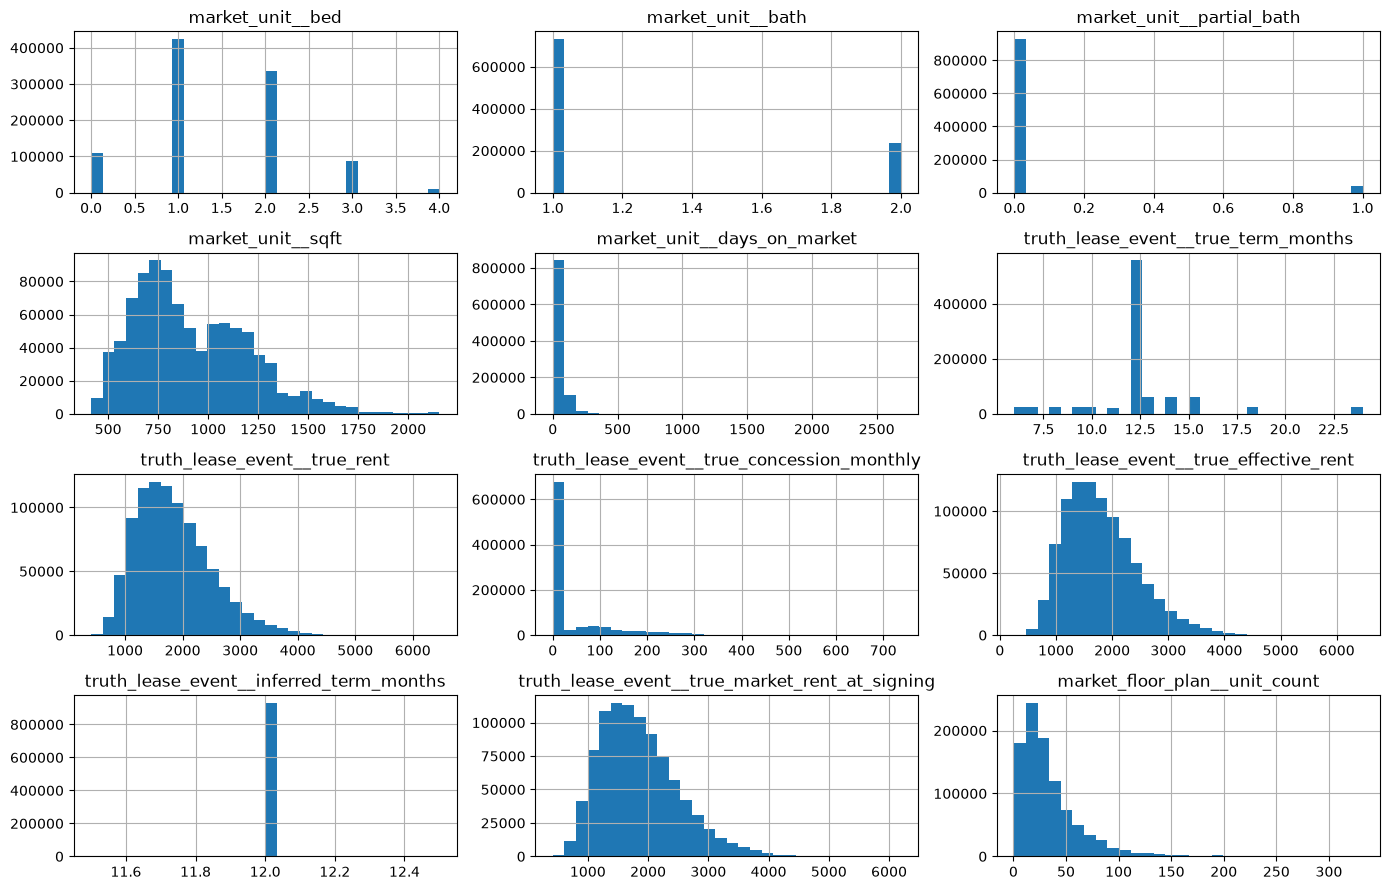

In [6]:
# Plot a sample of numeric predictors, excluding the target and boolean columns.
numeric_cols = [
    c for c in df_analysis.select_dtypes(include=np.number).columns
    if c != TARGET and not pd.api.types.is_bool_dtype(df_analysis[c])
]

plot_cols = numeric_cols[:12]

if plot_cols:
    df_analysis[plot_cols].hist(bins=30, figsize=(14, 9))
    plt.tight_layout()
    plt.show()
else:
    print("No numeric predictors are available to plot.")

## 5. Preparation for Supervised Analysis

The univariate pass criterion is that a predictor has more than one distinct non-missing value. Predictors must also meet the completeness threshold defined earlier. The bivariate and multivariate stages then apply their own explicit selection rules.

In [7]:
# Keep only rows where the target is present.
df_target = df_analysis.loc[df_analysis[TARGET].notna()].copy()

print(
    f"Rows with observed target: "
    f"{len(df_target):,} / {len(df_analysis):,}"
)

# Classify predictors by their actual pandas data types.
boolean_features = [
    c for c in predictor_candidates
    if c in df_target.columns and pd.api.types.is_bool_dtype(df_target[c])
]

datetime_features = [
    c for c in predictor_candidates
    if c in df_target.columns and pd.api.types.is_datetime64_any_dtype(df_target[c])
]

numeric_features = [
    c for c in predictor_candidates
    if c in df_target.columns
    and pd.api.types.is_numeric_dtype(df_target[c])
    and not pd.api.types.is_bool_dtype(df_target[c])
]

categorical_features = [
    c for c in predictor_candidates
    if c in df_target.columns
    and (
        pd.api.types.is_object_dtype(df_target[c])
        or pd.api.types.is_string_dtype(df_target[c])
        or isinstance(df_target[c].dtype, pd.CategoricalDtype)
    )
]

other_features = [
    c for c in predictor_candidates
    if c not in numeric_features
    and c not in boolean_features
    and c not in datetime_features
    and c not in categorical_features
]

feature_types = pd.DataFrame({
    "feature": predictor_candidates,
    "dtype": [str(df_target[c].dtype) for c in predictor_candidates],
    "feature_type": [
        "boolean" if c in boolean_features else
        "datetime" if c in datetime_features else
        "numeric" if c in numeric_features else
        "categorical" if c in categorical_features else
        "other"
        for c in predictor_candidates
    ],
})

display(feature_types["feature_type"].value_counts().rename_axis("feature_type").to_frame("count"))
display(feature_types)

Rows with observed target: 967,277 / 967,661


,count
feature_type,
boolean,215
numeric,66
categorical,28
datetime,9


,feature,dtype,feature_type
0,unit_id,string,categorical
1,property_id,string,categorical
2,floor_plan_id,string,categorical
3,market,string,categorical
4,market_unit__unit_name,string,categorical
...,...,...,...
313,market_leasing_activity_daily__leased_pct_at_e...,float64,numeric
314,market_leasing_activity_daily__exposure_pct_at...,float64,numeric
315,truth_floorplan_market_rent__true_market_rent_...,float64,numeric
316,truth_floorplan_market_rent__true_market_rent_...,float64,numeric


## 6. Bivariate Analysis — Relationship with the Target

In [8]:
# Calculate each numeric predictor's correlation with the target using pairwise available observations.
biv_rows = []

for col in numeric_features:
    pair = df_target[[col, TARGET]].apply(pd.to_numeric, errors="coerce").dropna()

    if len(pair) < 3 or pair[col].nunique() < 2 or pair[TARGET].nunique() < 2:
        corr = np.nan
    else:
        corr = pair[col].corr(pair[TARGET], method=CORRELATION_METHOD)

    biv_rows.append({
        "feature": col,
        "target": TARGET,
        "correlation": corr,
        "abs_correlation": abs(corr) if pd.notna(corr) else np.nan,
        "n_pairwise": len(pair),
        "passes_threshold": bool(pd.notna(corr) and abs(corr) >= BIVARIATE_THRESHOLD),
    })

biv_corr = pd.DataFrame(
    biv_rows,
    columns=[
        "feature", "target", "correlation", "abs_correlation",
        "n_pairwise", "passes_threshold"
    ],
).sort_values("abs_correlation", ascending=False, na_position="last")

display(biv_corr.head(40))
biv_corr.to_csv(OUTPUT_DIR / "02_bivariate_target_correlations.csv", index=False)

# Summarize the observed target values.
display(df_target[TARGET].describe().to_frame("target_summary"))

,feature,target,correlation,abs_correlation,n_pairwise,passes_threshold
47,market_price_observation__max_asking_rent,market_price_observation__first_asking_rent,0.998717,0.998717,967277,True
48,market_price_observation__day_weighted_asking_...,market_price_observation__first_asking_rent,0.998690,0.998690,967277,True
46,market_price_observation__min_asking_rent,market_price_observation__first_asking_rent,0.996307,0.996307,967277,True
57,market_price_observation__leased_asking_rent,market_price_observation__first_asking_rent,0.995389,0.995389,931354,True
45,market_price_observation__last_asking_rent,market_price_observation__first_asking_rent,0.995324,0.995324,967277,True
6,truth_lease_event__true_rent,market_price_observation__first_asking_rent,0.995174,0.995174,931354,True
49,market_price_observation__first_effective_rent,market_price_observation__first_asking_rent,0.994024,0.994024,967277,True
51,market_price_observation__day_weighted_effecti...,market_price_observation__first_asking_rent,0.993589,0.993589,967277,True
64,truth_floorplan_market_rent__true_market_rent_...,market_price_observation__first_asking_rent,0.991633,0.991633,953936,True
10,truth_lease_event__true_market_rent_at_signing,market_price_observation__first_asking_rent,0.989995,0.989995,931354,True


,target_summary
count,967277.000000
mean,1857.103647
std,657.902013
min,410.000000
25%,1365.000000
50%,1760.000000
75%,2243.000000
max,6500.000000


### Categorical Predictors: Target Summary by Category

In [9]:
# Summarize target values for low-cardinality categorical predictors.
cat_summary = []

for col in categorical_features:
    n_levels = df_target[col].nunique(dropna=True)

    if 1 < n_levels <= 50:
        grouped = (
            df_target.groupby(col, dropna=False)[TARGET]
            .agg(["count", "mean", "median"])
            .reset_index()
        )
        grouped.insert(0, "feature", col)
        grouped = grouped.rename(columns={
            col: "category",
            "mean": "target_mean",
            "median": "target_median",
        })
        cat_summary.append(grouped)

if cat_summary:
    cat_target_summary = pd.concat(cat_summary, ignore_index=True)
    display(cat_target_summary.head(100))
    cat_target_summary.to_csv(OUTPUT_DIR / "02_bivariate_categorical_target.csv", index=False)
else:
    print("No categorical predictors with 2 to 50 distinct levels were found.")

# Summarize target values separately for boolean predictors.
bool_summary = []

for col in boolean_features:
    grouped = (
        df_target.groupby(col, dropna=False)[TARGET]
        .agg(["count", "mean", "median"])
        .reset_index()
    )
    grouped.insert(0, "feature", col)
    grouped = grouped.rename(columns={
        col: "value",
        "mean": "target_mean",
        "median": "target_median",
    })
    bool_summary.append(grouped)

if bool_summary:
    bool_target_summary = pd.concat(bool_summary, ignore_index=True)
    display(bool_target_summary.head(100))
    bool_target_summary.to_csv(OUTPUT_DIR / "02_bivariate_boolean_target.csv", index=False)
else:
    print("No boolean predictors were found.")

,feature,category,count,target_mean,target_median
0,market,chicago,478226,1895.468084,1820.0
1,market,dc,195530,2284.638485,2185.0
2,market,dfw,293521,1509.793715,1426.0
3,market_unit__status,active,35923,2063.503354,1964.0
4,market_unit__status,closed,931354,1849.142660,1755.0
...,...,...,...,...,...
93,truth_building_params__building_form,mid_rise,370877,1876.163836,1780.0
94,truth_building_params__product_type,affordable,54673,1910.685055,1840.0
95,truth_building_params__product_type,market_rate,816015,1847.950979,1750.0
96,truth_building_params__product_type,senior,24167,1799.562668,1670.0


,feature,value,count,target_mean,target_median
0,market_building__is_apartment,False,65018,1900.711803,1785.0
1,market_building__is_apartment,True,902259,1853.961184,1760.0
2,market_building__is_condo,False,923871,1853.744770,1760.0
3,market_building__is_condo,True,43406,1928.595355,1785.0
4,market_building__is_single_family,False,944960,1857.873401,1760.0
...,...,...,...,...,...
95,market_building__amen__controlled_access,<NA>,166461,1811.855462,1705.0
96,market_building__amen__corporate_suite,False,782123,1861.644443,1770.0
97,market_building__amen__corporate_suite,True,18693,2070.049484,2000.0
98,market_building__amen__corporate_suite,<NA>,166461,1811.855462,1705.0


## 7. Multivariate Analysis — Redundancy and Feature Selection

In [10]:
# Stage 3: assess redundancy among numeric predictors that passed the bivariate stage.
# For each highly correlated pair, retain the feature with the stronger target correlation.

biv_corr_lookup = biv_corr.set_index("feature")["abs_correlation"].to_dict()

univariate_pass = {
    c: bool(df[c].notna().sum() >= 1 and df[c].nunique(dropna=True) > 1)
    for c in predictor_candidates
}

bivariate_pass = {
    c: bool(
        c in biv_corr_lookup
        and pd.notna(biv_corr_lookup[c])
        and biv_corr_lookup[c] >= BIVARIATE_THRESHOLD
    )
    for c in predictor_candidates
}

bivariate_candidates = [
    c for c in numeric_features
    if univariate_pass.get(c, False) and bivariate_pass.get(c, False)
]

if len(bivariate_candidates) >= 2:
    corr_matrix = df_target[bivariate_candidates].corr(method=CORRELATION_METHOD)
    corr_matrix.to_csv(OUTPUT_DIR / "03_multivariate_correlation_matrix.csv")

    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
    pairs = (
        upper.stack()
        .rename("correlation")
        .reset_index()
        .rename(columns={"level_0": "feature_1", "level_1": "feature_2"})
    )
    pairs["abs_correlation"] = pairs["correlation"].abs()
    pairs["high_correlation"] = pairs["abs_correlation"] >= MULTIVARIATE_THRESHOLD
    pairs = pairs.sort_values("abs_correlation", ascending=False).reset_index(drop=True)
    display(pairs.head(50))
    display(pairs[pairs["high_correlation"]])
    
    # Greedy redundancy filter: keep the feature with the stronger absolute target correlation.
    selected_numeric = set(bivariate_candidates)
    high_corr_pairs = pairs.loc[pairs["high_correlation"]].sort_values(
        "abs_correlation", ascending=False
    )
    for _, pair in high_corr_pairs.iterrows():
        f1, f2 = pair["feature_1"], pair["feature_2"]
        if f1 in selected_numeric and f2 in selected_numeric:
            score1 = biv_corr_lookup.get(f1, np.nan)
            score2 = biv_corr_lookup.get(f2, np.nan)
            # If scores tie or are unavailable, drop the second feature deterministically.
            if pd.isna(score1) or (pd.notna(score2) and score2 > score1):
                selected_numeric.remove(f1)
            else:
                selected_numeric.remove(f2)
else:
    corr_matrix = pd.DataFrame()
    pairs = pd.DataFrame(columns=["feature_1", "feature_2", "correlation", "abs_correlation", "high_correlation"])
    selected_numeric = set(bivariate_candidates)
    print("At least two bivariate-passing numeric predictors are required to assess redundancy.")

multivariate_pass = {c: c in selected_numeric for c in predictor_candidates}

print(f"Numeric predictors passing univariate stage: {sum(univariate_pass.get(c, False) for c in numeric_features):,}")
print(f"Numeric predictors passing bivariate stage: {len(bivariate_candidates):,}")
print(f"Numeric predictors retained after multivariate filtering: {len(selected_numeric):,}")

,feature_1,feature_2,correlation,abs_correlation,high_correlation
0,market_price_observation__last_asking_rent_psf,market_price_observation__leased_asking_rent_psf,1.000000,1.000000,True
1,market_building__number_units,truth_building_params__number_units_true,1.000000,1.000000,True
2,market_price_observation__last_effective_rent,market_price_observation__leased_effective_rent,1.000000,1.000000,True
3,market_price_observation__last_asking_rent,market_price_observation__leased_asking_rent,1.000000,1.000000,True
4,truth_lease_event__true_rent,market_price_observation__leased_asking_rent,0.999773,0.999773,True
5,truth_lease_event__true_rent,market_price_observation__last_asking_rent,0.999773,0.999773,True
6,truth_lease_event__true_effective_rent,market_price_observation__last_effective_rent,0.999361,0.999361,True
7,truth_lease_event__true_effective_rent,market_price_observation__leased_effective_rent,0.999361,0.999361,True
8,market_price_observation__max_asking_rent,market_price_observation__day_weighted_asking_...,0.998950,0.998950,True
9,market_price_observation__min_asking_rent,market_price_observation__day_weighted_asking_...,0.998391,0.998391,True


,feature_1,feature_2,correlation,abs_correlation,high_correlation
0,market_price_observation__last_asking_rent_psf,market_price_observation__leased_asking_rent_psf,1.000000,1.000000,True
1,market_building__number_units,truth_building_params__number_units_true,1.000000,1.000000,True
2,market_price_observation__last_effective_rent,market_price_observation__leased_effective_rent,1.000000,1.000000,True
3,market_price_observation__last_asking_rent,market_price_observation__leased_asking_rent,1.000000,1.000000,True
4,truth_lease_event__true_rent,market_price_observation__leased_asking_rent,0.999773,0.999773,True
...,...,...,...,...,...
106,market_building__count_reviews,market_building__positive_location,0.891736,0.891736,True
107,market_building__positive_location,market_building__positive_value,0.883837,0.883837,True
108,market_building__n_building_amenities,market_building__n_unit_amenities,0.871174,0.871174,True
109,market_building__number_units,market_building__count_reviews,0.827086,0.827086,True


Numeric predictors passing univariate stage: 65
Numeric predictors passing bivariate stage: 44
Numeric predictors retained after multivariate filtering: 18


## 8. Final Feature Selection and Outputs

In [11]:
# Build a stage-by-stage selection summary for every predictor.
selection_rows = []

for c in predictor_candidates:
    is_numeric = c in numeric_features
    uni_pass = univariate_pass.get(c, False)
    biv_pass = bivariate_pass.get(c, False) if is_numeric else False
    multi_pass = multivariate_pass.get(c, False) if is_numeric and biv_pass else False

    if not uni_pass:
        status = "Rejected at univariate stage"
    elif not is_numeric:
        status = "Not evaluated by numeric bivariate criterion"
    elif not biv_pass:
        status = "Rejected at bivariate stage"
    elif not multi_pass:
        status = "Removed at multivariate stage (redundant)"
    else:
        status = "Passed all three stages"

    selection_rows.append({
        "feature": c,
        "dtype": str(df[c].dtype),
        "feature_type": feature_types.loc[feature_types["feature"].eq(c), "feature_type"].iloc[0],
        "completeness_pct": round(df[c].notna().mean() * 100, 2),
        "univariate_pass": uni_pass,
        "bivariate_pass": biv_pass,
        "multivariate_pass": multi_pass,
        "selection_status": status,
        "final_selected": bool(uni_pass and biv_pass and multi_pass),
    })

selection_summary = pd.DataFrame(selection_rows)
final_selected_features = selection_summary.loc[
    selection_summary["selection_status"].eq("Passed all three stages"), "feature"
].tolist()

display(selection_summary["selection_status"].value_counts().rename_axis("selection_status").to_frame("count"))
display(selection_summary)
selection_summary.to_csv(OUTPUT_DIR / "04_feature_selection_stages.csv", index=False)

final_features_df = selection_summary[
    selection_summary["feature"].isin(final_selected_features)
].copy()
final_features_df.to_csv(OUTPUT_DIR / "04_final_selected_features.csv", index=False)

print(f"Final selected features (passed all three stages): {len(final_selected_features):,}")
print("Outputs saved to:", OUTPUT_DIR.resolve())
print("- column_profile.csv")
print("- univariate_summary.csv")
print("- feature_types.csv")
print("- bivariate_target_correlations.csv")
print("- bivariate_categorical_target.csv (if applicable)")
print("- bivariate_boolean_target.csv (if applicable)")
print("- multivariate_correlation_matrix.csv (if applicable)")
print("- multivariate_correlated_pairs.csv (if applicable)")
print("- feature_selection_stages.csv")
print("- final_selected_features.csv")

,count
selection_status,
Not evaluated by numeric bivariate criterion,252
Removed at multivariate stage (redundant),26
Rejected at bivariate stage,21
Passed all three stages,18
Rejected at univariate stage,1


,feature,dtype,feature_type,completeness_pct,univariate_pass,bivariate_pass,multivariate_pass,selection_status,final_selected
0,unit_id,string,categorical,100.00,True,False,False,Not evaluated by numeric bivariate criterion,False
1,property_id,string,categorical,100.00,True,False,False,Not evaluated by numeric bivariate criterion,False
2,floor_plan_id,string,categorical,100.00,True,False,False,Not evaluated by numeric bivariate criterion,False
3,market,string,categorical,100.00,True,False,False,Not evaluated by numeric bivariate criterion,False
4,market_unit__unit_name,string,categorical,89.22,True,False,False,Not evaluated by numeric bivariate criterion,False
...,...,...,...,...,...,...,...,...,...
313,market_leasing_activity_daily__leased_pct_at_e...,float64,numeric,90.49,True,False,False,Rejected at bivariate stage,False
314,market_leasing_activity_daily__exposure_pct_at...,float64,numeric,90.49,True,True,True,Passed all three stages,True
315,truth_floorplan_market_rent__true_market_rent_...,float64,numeric,98.58,True,True,False,Removed at multivariate stage (redundant),False
316,truth_floorplan_market_rent__true_market_rent_...,float64,numeric,98.58,True,True,False,Removed at multivariate stage (redundant),False


Final selected features (passed all three stages): 18
Outputs saved to: /Users/ladyinfante/Documents/MSDS/01. Courses/04. Fall 2026/Data Science Capstone & Ethics/From-Listings-to-Intelligence/outputs/modeling_funnel
- column_profile.csv
- univariate_summary.csv
- feature_types.csv
- bivariate_target_correlations.csv
- bivariate_categorical_target.csv (if applicable)
- bivariate_boolean_target.csv (if applicable)
- multivariate_correlation_matrix.csv (if applicable)
- multivariate_correlated_pairs.csv (if applicable)
- feature_selection_stages.csv
- final_selected_features.csv


In [12]:
final_features_df.query('final_selected==True').shape
final_features_df.query('final_selected==True')

,feature,dtype,feature_type,completeness_pct,univariate_pass,bivariate_pass,multivariate_pass,selection_status,final_selected
7,market_unit__bath,int64,numeric,100.00,True,True,True,Passed all three stages,True
9,market_unit__sqft,float64,numeric,95.67,True,True,True,Passed all three stages,True
30,market_floor_plan__unit_count,int64,numeric,100.00,True,True,True,Passed all three stages,True
38,market_building__lat,float64,numeric,100.00,True,True,True,Passed all three stages,True
39,market_building__lon,float64,numeric,100.00,True,True,True,Passed all three stages,True
55,market_building__avg_price_duration_days,float64,numeric,100.00,True,True,True,Passed all three stages,True
56,market_building__avg_price_change,float64,numeric,100.00,True,True,True,Passed all three stages,True
58,market_building__count_prices,int64,numeric,100.00,True,True,True,Passed all three stages,True
61,market_building__avg_review_score,float64,numeric,100.00,True,True,True,Passed all three stages,True
66,market_building__positive_cleanliness_and_main...,int64,numeric,100.00,True,True,True,Passed all three stages,True
